# Local iron environments from real nuclear transmission spectra

## Problem and observations
Four independently calibrated USGS vermiculite-ore spectra constrain iron-site isomer shifts, full quadrupole splittings, absorber line widths and effective optical thicknesses. The observations come from295K conventional57Co/Rh measurements; the algorithm is the selected SYNCmoss transmission-integral/custom-LM method. These are different publication sources. We reproduce no original SYNCmoss sample or figure, and no measured true site parameters are available.

In [1]:
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks':root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct,outputs,configuration,paired_lm,jacobian
from src.physics_model import transmission
velocity,observed=load_data(root/'data/raw_data.npz')
with np.load(root/'notebooks/reference_outputs/upstream_measurements.npz') as f:upstream={k:f[k] for k in f.files}
print('Real specimen/channel dimensions:',observed.shape)
print('Only source Velocity/Data columns are used; no source fitted components enter observations or initialization.')

Real specimen/channel dimensions: (4, 512)
Only source Velocity/Data columns are used; no source fitted components enter observations or initialization.


## Physics and selected method
Each site contributes a symmetric absorption doublet with centers delta±QS/2, where delta is isomer shift and QS full quadrupole splitting, both expressed as Doppler velocities in mm/s. The absorber optical depth is the sum of Lorentzian line densities weighted by effective resonant optical thickness. Intensity is exp(-optical depth), convolved with the natural source Lorentzian, then multiplied by a specimen baseline. For an isotropic powder the original complex2x2 cross-section is scalar; dispersive phase cancels in transmitted intensity. The local scalar formula is therefore the exact selected branch, not an unrelated thin-absorption replacement.

The64-node source quadrature, finite-wing correction, natural linewidth, parameter bounds, forward numerical Jacobian, Gaussian-elimination LM step, alternating damping and source stopping conventions are explicit. Two independent generic chemical initial mixtures guard against poor local minima. Unknown recoil fractions prevent equating effective thickness with measured iron abundance.

In [2]:
tick=time.perf_counter();fresh,records=reconstruct(velocity,observed);runtime=time.perf_counter()-tick
np.savez_compressed(root/'output/reconstruction.npz',**fresh)
np.savez_compressed(root/'notebooks/reference_outputs/fresh_notebook_result.npz',**fresh)
print('Full active inversion seconds:',runtime)
for i,r in enumerate(records):print('Specimen',i+1,'two fresh start SSE:',r['starts_sse'])
reference=outputs(upstream['params'],velocity);reference['transmission']=upstream['prediction'][None]
import importlib.util
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
metrics,thresholds=judge.score(fresh,reference,velocity,observed,json.loads((root/'evaluation/metrics.json').read_text()))
for name,value in metrics.items():print(name,value,'<=',thresholds[name]['boundary'])
assert all(metrics[k]<=r['boundary'] for k,r in thresholds.items())

Full active inversion seconds: 16.016381099936552
Specimen 1 two fresh start SSE: [9.796095039928477e-05, 9.425522714174206e-05]
Specimen 2 two fresh start SSE: [0.00027875605390139237, 0.0003014496555695892]
Specimen 3 two fresh start SSE: [0.00038192334468208674, 0.0003819287659066172]
Specimen 4 two fresh start SSE: [0.00033366373446257436, 0.00047798880055167995]
isomer_shift_mm_per_s 8.826720635290997e-06 <= 0.001
quadrupole_splitting_mm_per_s 6.593085029482637e-06 <= 0.001
FWHM_mm_per_s 1.6098837655992293e-05 <= 0.001
optical_thickness_maximum_absolute_error 3.0800365808797414e-06 <= 0.002
baseline_maximum_absolute_error 2.412874455792746e-09 <= 1e-05
transmission_maximum_absolute_error 1.394953333955229e-07 <= 1e-05
parameter_spectrum_self_consistency 2.220446049250313e-16 <= 1e-08
observed_transmission_RMS_sample_0 0.0004290597167192639 <= 0.00047196639075561817
observed_transmission_RMS_sample_1 0.0007378654469319979 <= 0.0008116519920623166
observed_transmission_RMS_sample_2 

## Full spectra, residuals and hyperfine parameters
Every original measured point is shown. Isomer shifts and splittings constrain iron environments, but four fitted components do not by themselves prove four chemically distinct species. Canonical labels only fix permutation freedom; they are not external site assignments.

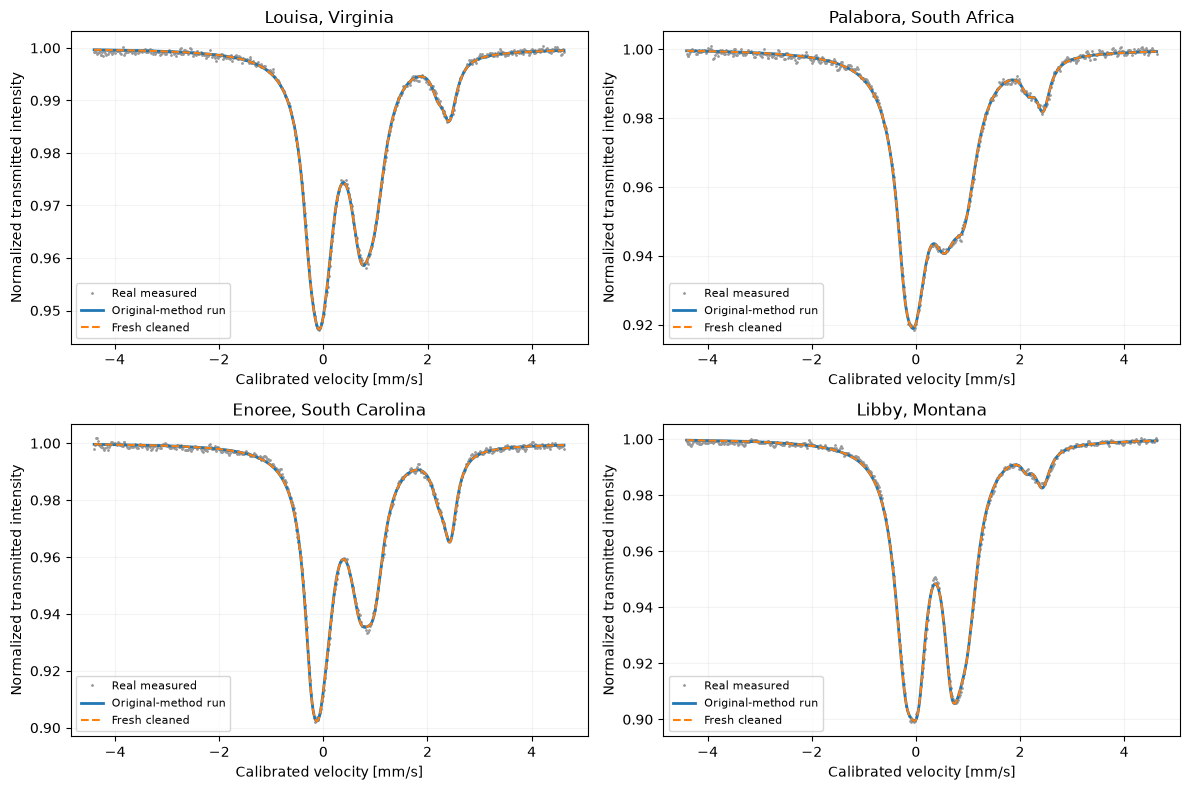

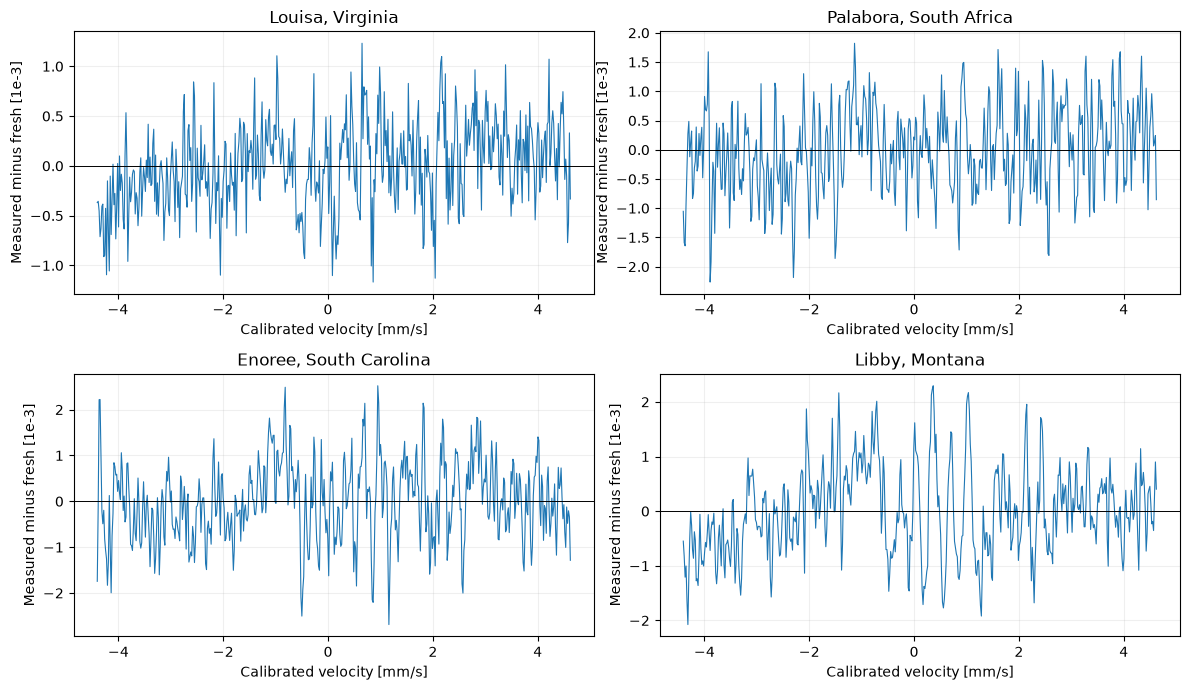

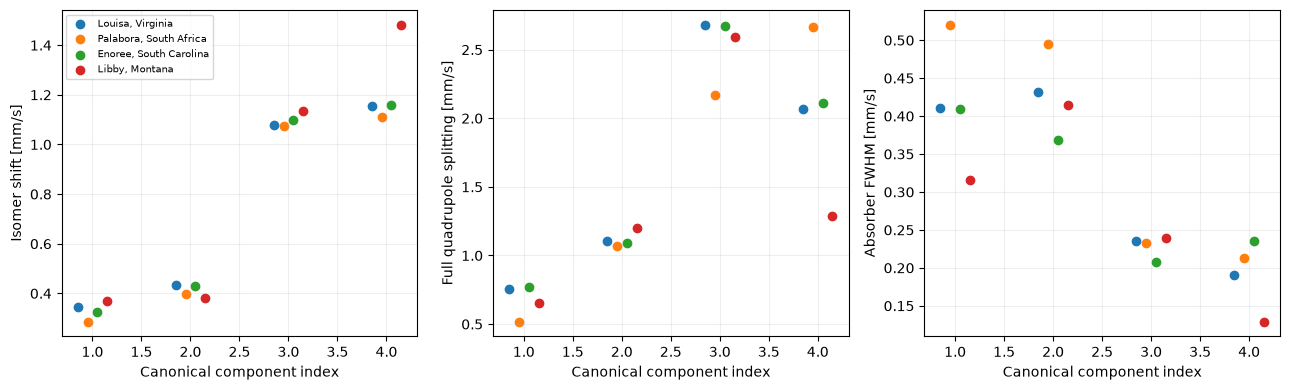

In [3]:
from src.visualization import review_figures
figures=review_figures(velocity,observed,fresh,upstream)
for fig in figures:display(fig)
plt.close('all')

## Component necessity and local minima
The independently executed original1/2/3/4-doublet fits below are labeled original diagnostic measurements. The original four-component alternative start reaches a poor local minimum for Libby: a nearly zero narrow component is not an equally valid site assignment. The standard retains the lower-SSE result from the two independent starts. Fresh local three-component fits provide an active simpler-model comparison under the same measured observations and forward physics. BIC here is n log(SSE/n)+p log(n), with n channel count and p=1+4 times component count; it assumes equal independent Gaussian variance and is a diagnostic, not proof of molecular identity.

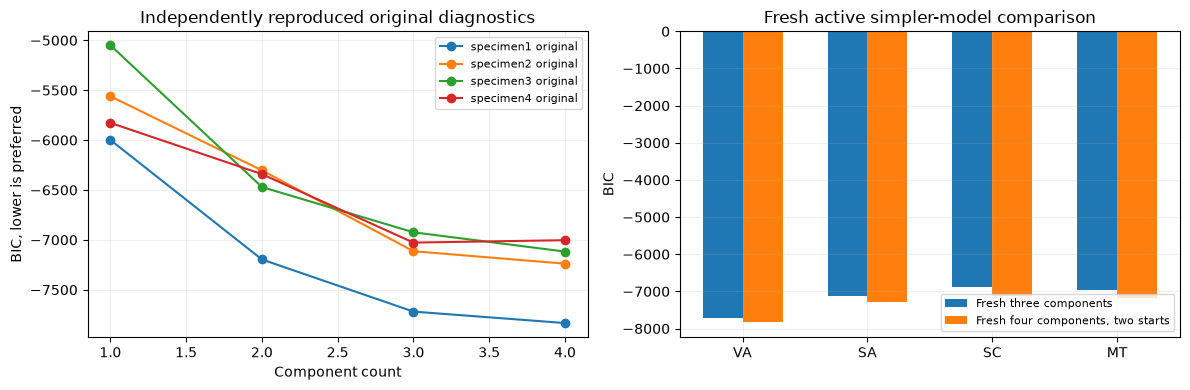

In [4]:
original=json.loads((root/'notebooks/reference_outputs/original_model_comparisons.json').read_text())
fresh_three=[]
for i in range(4):
    p,fixed,bounds=configuration(count=3)
    fit,history=paired_lm(velocity[i],observed[i],p,fixed,bounds)
    sse=float(np.sum((transmission(velocity[i],fit)-observed[i])**2))
    fresh_three.append({'sse':sse,'bic':float(512*np.log(sse/512)+13*np.log(512))})
fig,axes=plt.subplots(1,2,figsize=(12,4))
files=list(dict.fromkeys(r['file'] for r in original))
for i,file in enumerate(files):
    group=[r for r in original if r['file']==file]
    axes[0].plot([r['components'] for r in group],[r['bic'] for r in group],'o-',label=f'specimen{i+1} original')
standard_bic=np.array([512*np.log(r['sse']/512)+17*np.log(512) for r in records])
axes[1].bar(np.arange(4)-.16,[r['bic'] for r in fresh_three],.32,label='Fresh three components')
axes[1].bar(np.arange(4)+.16,standard_bic,.32,label='Fresh four components, two starts')
axes[0].set(xlabel='Component count',ylabel='BIC, lower is preferred',title='Independently reproduced original diagnostics')
axes[1].set(xticks=np.arange(4),xticklabels=['VA','SA','SC','MT'],ylabel='BIC',title='Fresh active simpler-model comparison')
for ax in axes:ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.tight_layout();display(fig);plt.close(fig)

## Conditioning and component interpretation
The singular values below use the fresh fitted numerical Jacobian normalized by column length, separating scale effects from correlation. Small singular values indicate correlated site descriptions. This is local model conditioning, not an independently measured uncertainty interval. Individual components are also shown in isolation: their transmitted intensities cannot be added, because optical depths add before exponentiation.

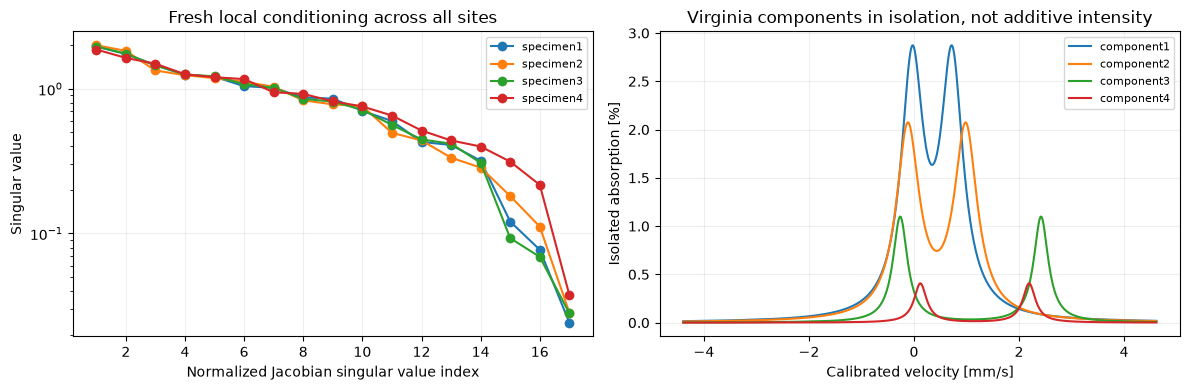

1237

In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for i in range(4):
    # Recover the selected full parameter vector from canonical fresh quantities.
    params=[float(fresh['baseline'][0,i]),0.,0.,0.,0.,0.,0.,0.]
    for site,I in zip(fresh['reconstruction'][0,i],fresh['optical_thickness'][0,i]):params.extend([I,site[0],site[1]/2,site[2],0.,0.,0.,0.,1.])
    params=np.array(params);free=[0]+[8+9*j+k for j in range(4) for k in [0,1,2,3]];fixed=np.setdiff1d(np.arange(44),free)
    J,_=jacobian(transmission,params,velocity[i],fixed,transmission(velocity[i],params));J=J/np.linalg.norm(J,axis=1)[:,None]
    axes[0].semilogy(np.arange(1,len(J)+1),np.linalg.svd(J,compute_uv=False),'o-',label=f'specimen{i+1}')
    if i==0:
        for k in range(4):
            isolated=params.copy();isolated[8::9]=0;isolated[8+9*k]=params[8+9*k];isolated[0]=1.
            axes[1].plot(velocity[i],100*(1-transmission(velocity[i],isolated)),label=f'component{k+1}')
axes[0].set(xlabel='Normalized Jacobian singular value index',ylabel='Singular value',title='Fresh local conditioning across all sites')
axes[1].set(xlabel='Calibrated velocity [mm/s]',ylabel='Isolated absorption [%]',title='Virginia components in isolation, not additive intensity')
for ax in axes:ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.tight_layout();display(fig);plt.close(fig)
(root/'notebooks/reference_outputs/cleaned_measurements.json').write_text(json.dumps({'runtime_s':runtime,'metrics':metrics,'four_component_sse':[r['sse'] for r in records],'fresh_three_component':fresh_three},indent=2),encoding='utf8')

## Conclusion
The fresh four-specimen inversion satisfies the independently frozen original parameter/spectrum gates and measured-residual checks. The selected four-component fits improve over simpler descriptions, while local conditioning and alternative-start minima limit chemical uniqueness. Results are numerical method references, not actual true iron-site populations. Source conventions and the exact data-processing provenance remain in validation.

Method: Yaroslavtsev, J. Synchrotron Radiat.30(2023),596–604, DOI10.1107/S1600577523001686. Data: Swayze etal., American Mineralogist103(2018),517–549, DOI10.2138/am-2018-6022; USGS release DOI10.5066/F7JM27SR.